# 01 · Exploratory Data Analysis — UCI Heart Disease (Cleveland)
The notebook calls the same functions as `python -m heart.eda`, so figures here and in CI are identical.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / 'src'), str(ROOT)]

In [2]:
import pandas as pd
from heart.data import load_clean
from heart import config
df = load_clean()
print(df.shape)
df.head()

(302, 14)


,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp,restecg,slope,thal,target
0,63,145.0,233.0,150.0,2.3,0.0,1,1,0,typical_angina,lv_hypertrophy,downsloping,fixed_defect,0
1,37,130.0,250.0,187.0,3.5,0.0,1,0,0,non_anginal,normal,downsloping,normal,0
2,41,130.0,204.0,172.0,1.4,0.0,0,0,0,atypical_angina,lv_hypertrophy,upsloping,normal,0
3,56,120.0,236.0,178.0,0.8,0.0,1,0,0,atypical_angina,normal,upsloping,normal,0
4,57,120.0,354.0,163.0,0.6,0.0,0,0,1,asymptomatic,normal,upsloping,normal,0


## Data quality
Missing values are rare (`ca`: 4, `thal`: 2). They are **not** dropped here: imputation lives inside the model pipeline so training and serving behave identically.

In [3]:
df.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2
ca,298.0,0.67,0.94,0.0,0.00,0.0,1.00,3.0
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
fbs,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
exang,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0
target,302.0,0.46,0.50,0.0,0.00,0.0,1.00,1.0


## Class balance
~54% no disease vs ~46% disease → roughly balanced, so accuracy is meaningful, but ROC-AUC is used for model selection.

In [5]:
df.target.value_counts(normalize=True).round(3)

target
0    0.543
1    0.457
Name: proportion, dtype: float64

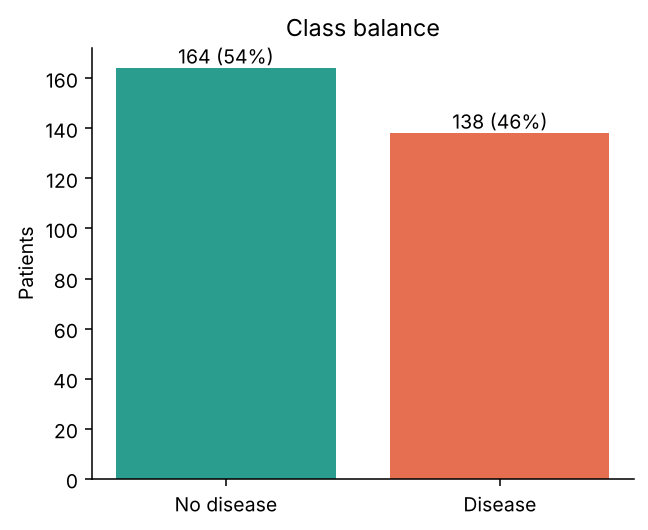

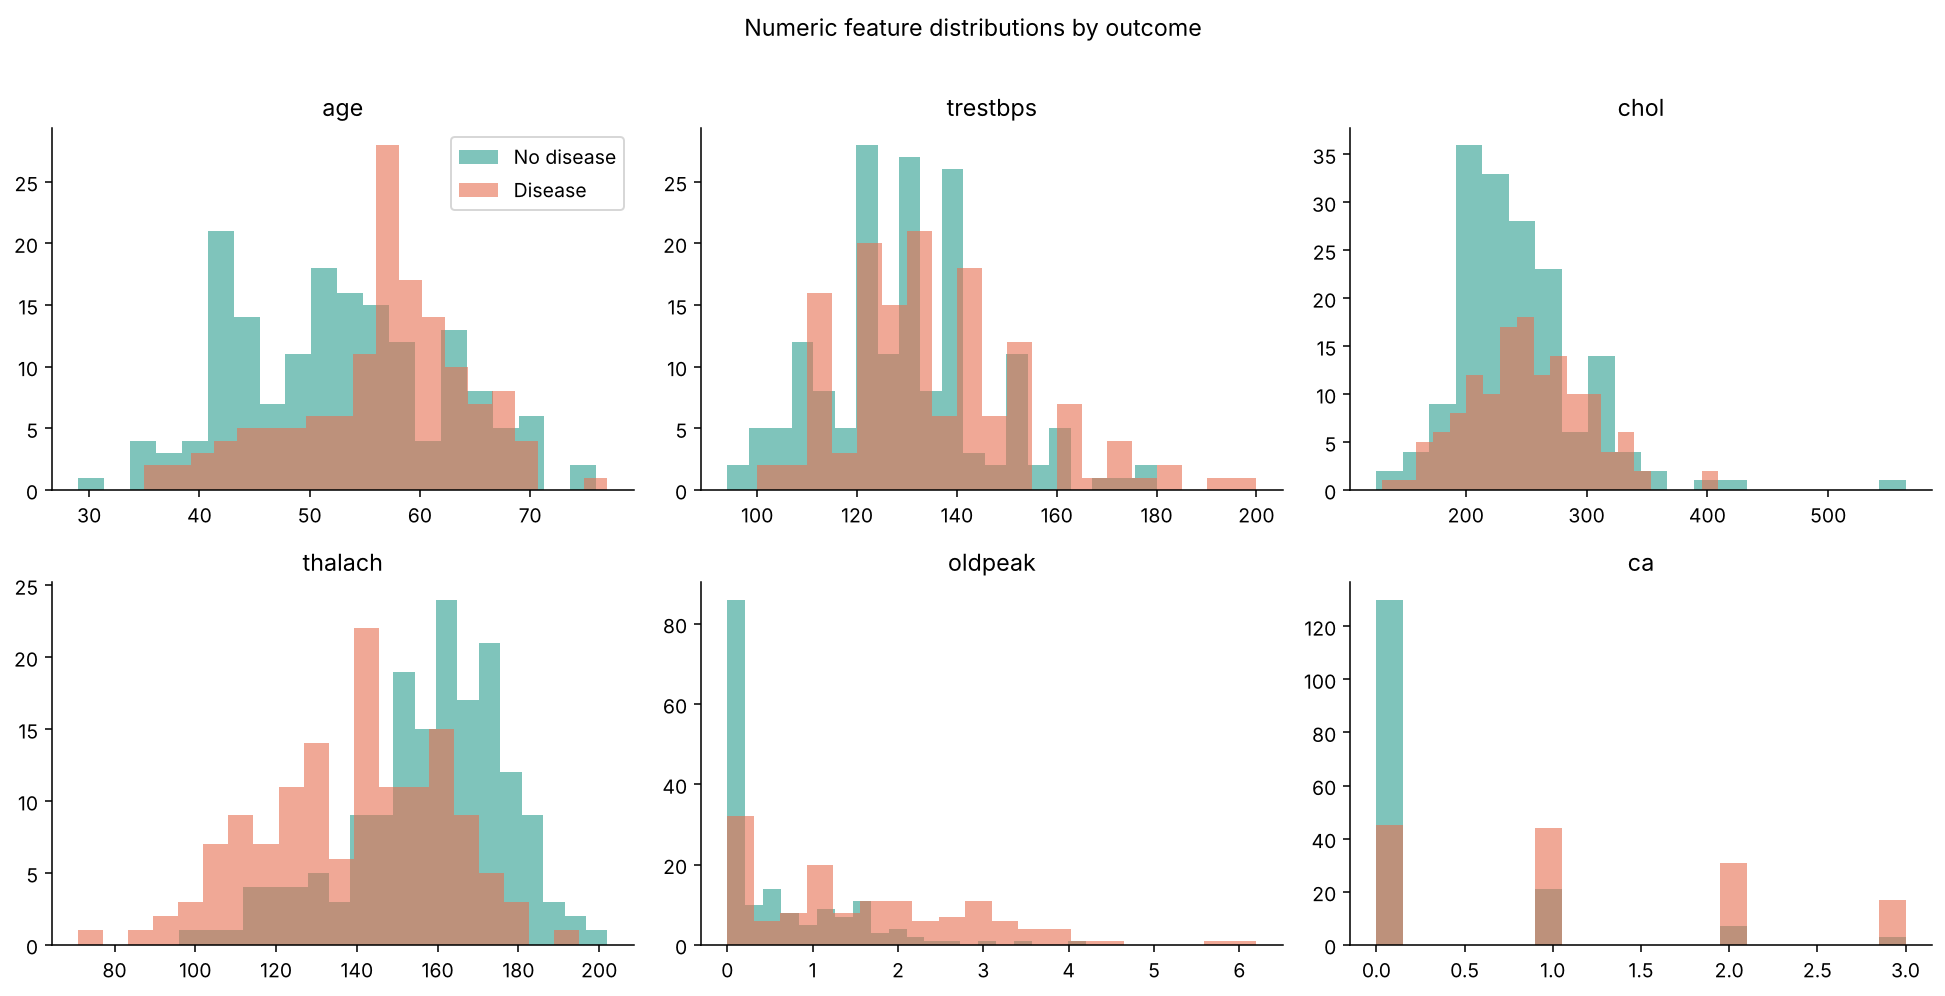

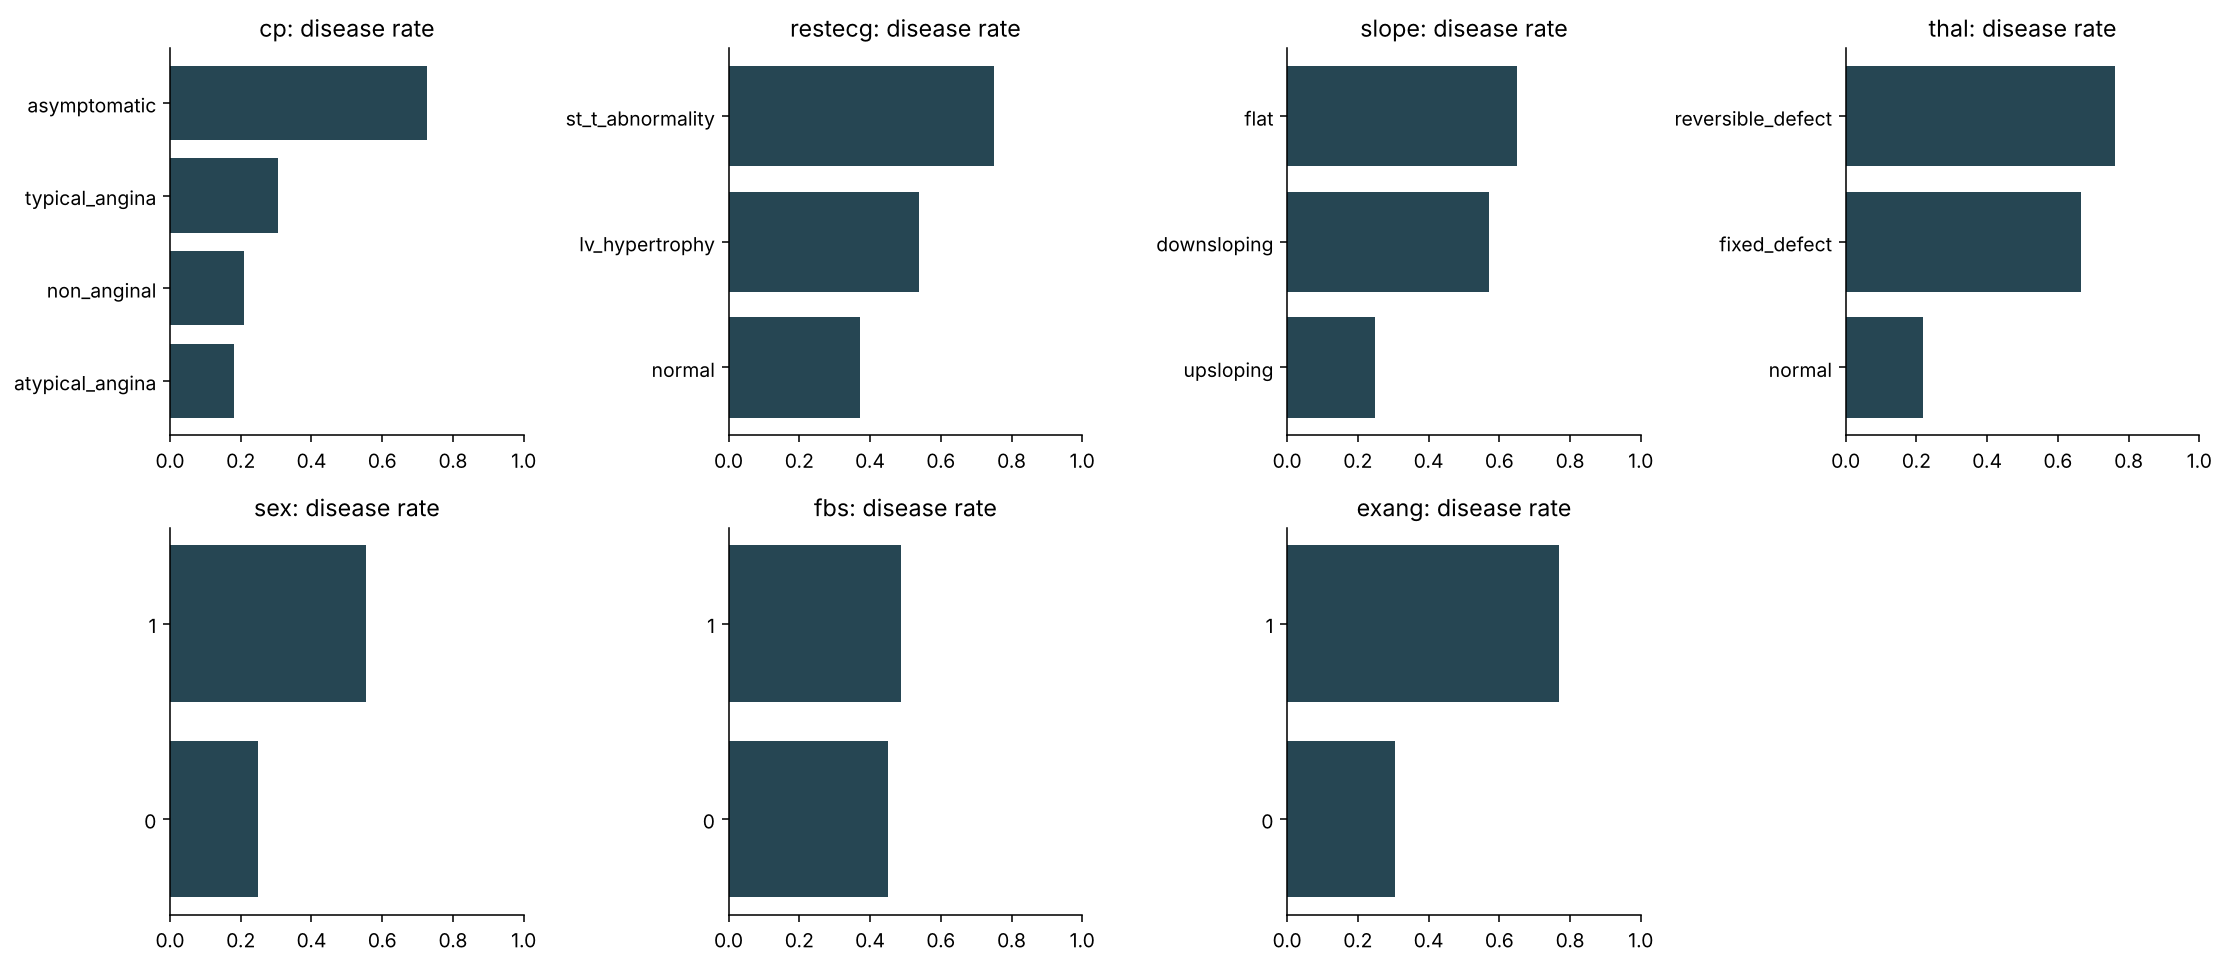

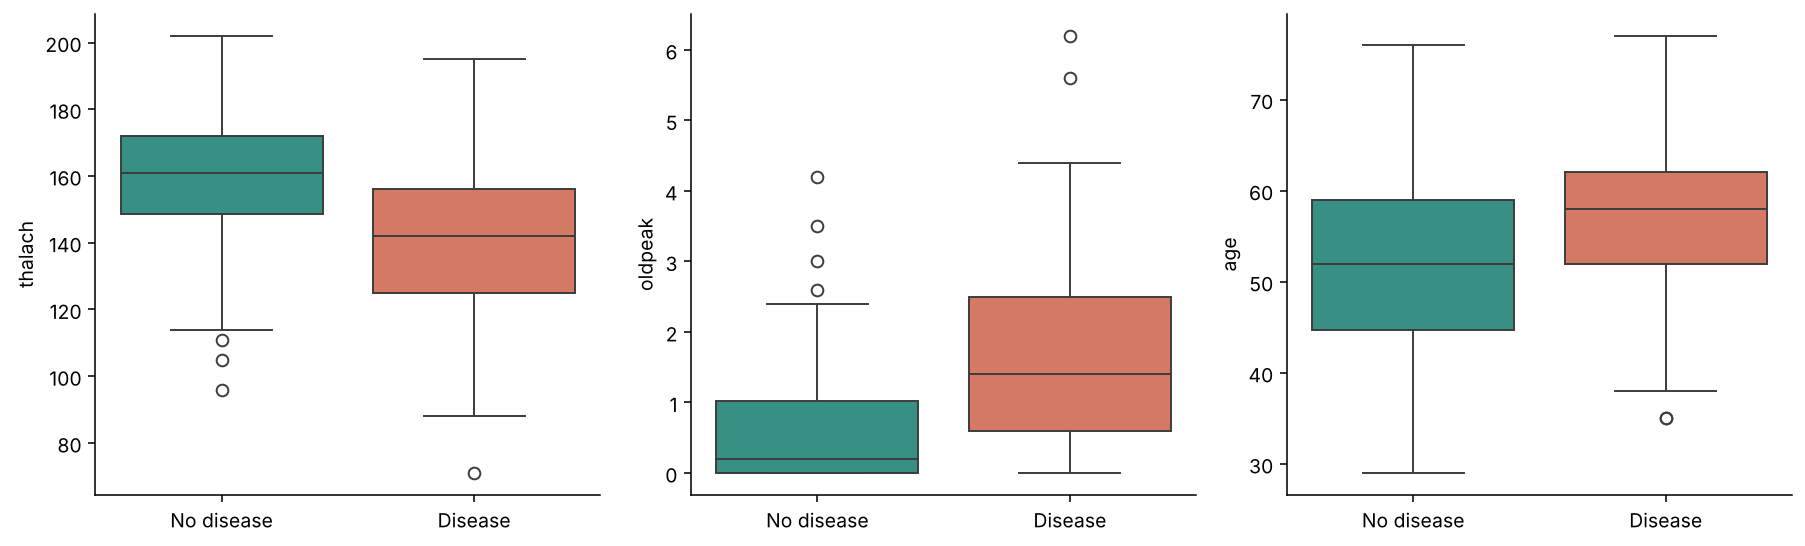

In [6]:
from heart import eda
from IPython.display import Image, display
for fn in [eda.class_balance, eda.numeric_histograms, eda.categorical_rates, eda.boxplots]:
    display(Image(filename=str(fn(df))))

## Correlations

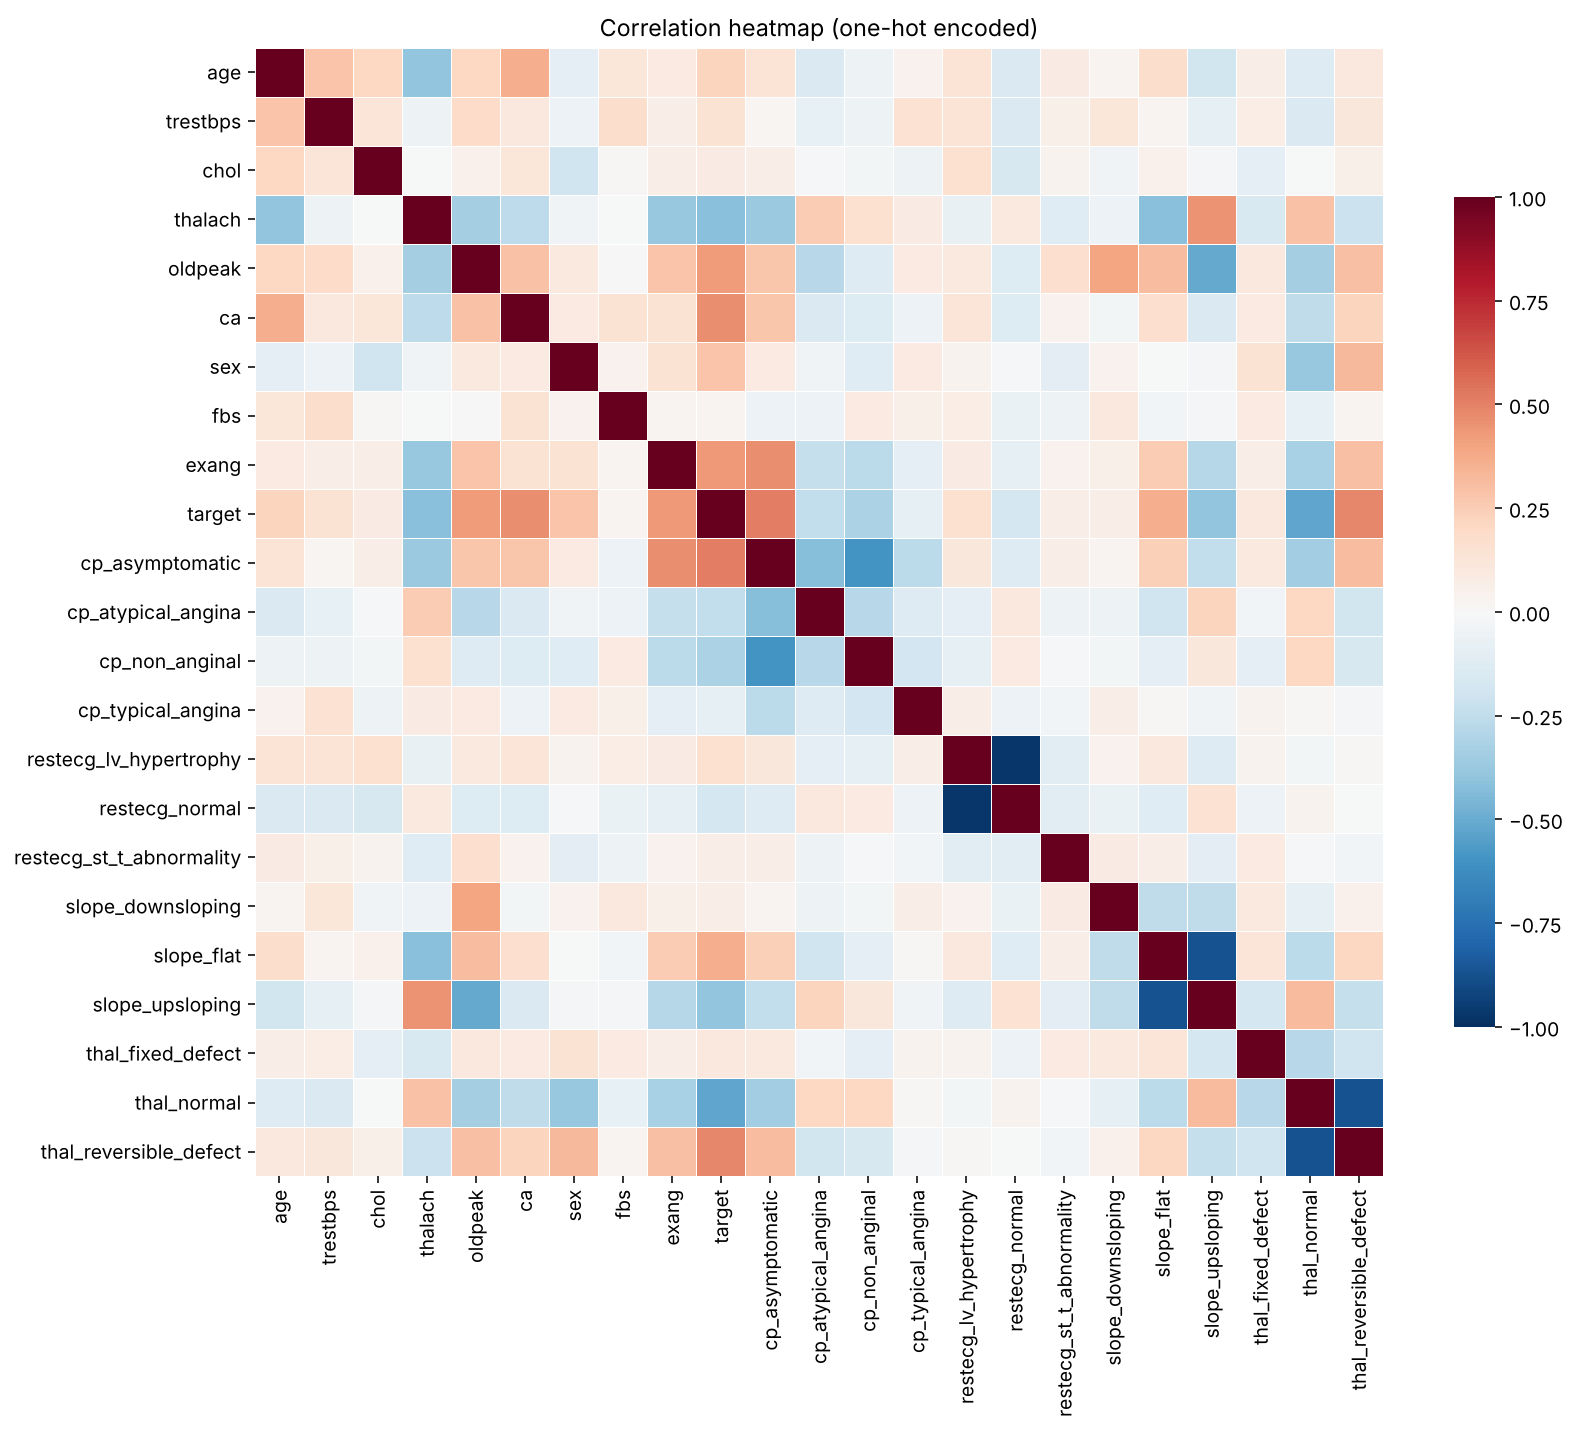

thal_normal                -0.526
thalach                    -0.420
slope_upsloping            -0.392
cp_non_anginal             -0.314
cp_atypical_angina         -0.248
restecg_normal             -0.173
cp_typical_angina          -0.088
fbs                         0.027
slope_downsloping           0.063
restecg_st_t_abnormality    0.068
chol                        0.081
thal_fixed_defect           0.106
trestbps                    0.146
restecg_lv_hypertrophy      0.157
age                         0.221
sex                         0.284
slope_flat                  0.360
oldpeak                     0.429
exang                       0.436
ca                          0.464
thal_reversible_defect      0.485
cp_asymptomatic             0.515
Name: target, dtype: float64

In [7]:
corr = eda.correlation_heatmap(df)
display(Image(filename=str(config.FIGURES_DIR / '04_correlation_heatmap.png')))
corr.round(3)

## Observations
- Strongest positive associations with disease: asymptomatic chest pain, reversible thal defect, exercise-induced angina, `oldpeak`, number of vessels `ca`.
- Lower max heart rate (`thalach`) is associated with disease.
- Cholesterol and resting BP show weak separation on their own.
- Nominal codes (`cp`, `thal`, `slope`, `restecg`) have no natural order → one-hot encoding, not ordinal integers.